In [1]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


/home/jpalmo/.conda/envs/tf/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-22 22:16:31.444617: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-22 22:16:31.446067: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 22:16:31.449472: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 22:16:31.459498: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register 

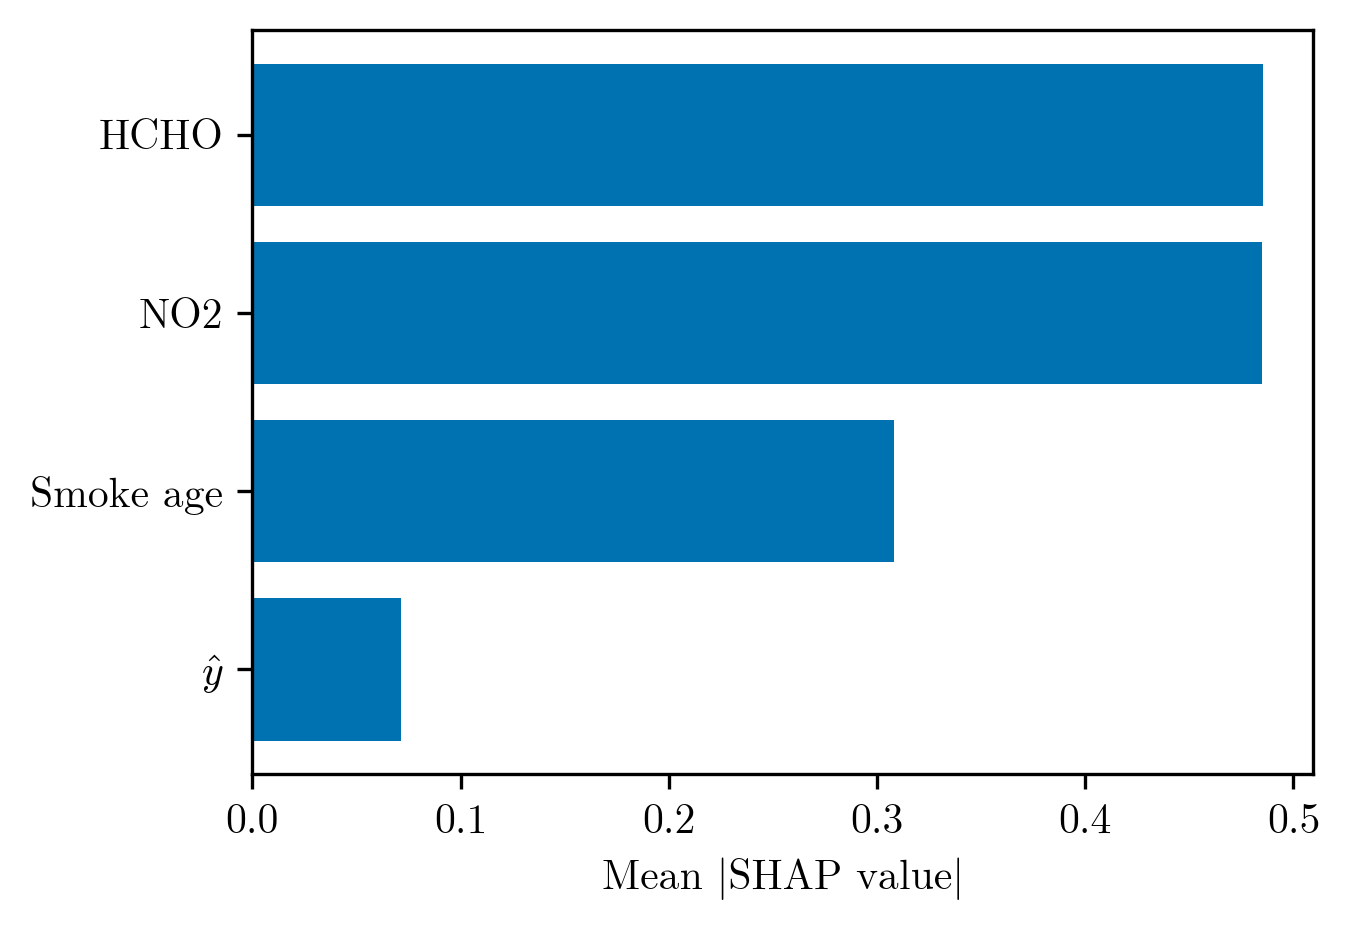

In [2]:
%matplotlib inline

import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from tensorflow import keras

MODEL_DIR = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/data")
DATA = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/data/training_data_po3.csv")
FEATURES = ["smoke_age", "normalized_distance_to_center", "CH2O", "NO2"]
LABELS = ["Smoke age", r"$\hat{y}$", "HCHO", "NO2"]
TEST_FIRE = 1.0

data = pd.read_csv(DATA)
data = data[FEATURES + ["pO3", "fire_id"]].dropna()
data = data[data["pO3"] > 0]
train = data[data["fire_id"] != TEST_FIRE]
test = data[data["fire_id"] == TEST_FIRE]
with (MODEL_DIR / "po3_scaler.pkl").open("rb") as handle:
    scaler = pickle.load(handle)
model = keras.models.load_model(MODEL_DIR / "po3_nn_model.keras")

rng = np.random.default_rng(0)
background = scaler.transform(train[FEATURES].sample(80, random_state=0))
explain = scaler.transform(test[FEATURES].sample(80, random_state=1))

def predict(x):
    return model.predict(x, verbose=0).ravel()

explainer = shap.KernelExplainer(predict, background)
values = explainer.shap_values(explain, nsamples=40)
values = np.asarray(values)
if values.ndim == 3:
    values = values[0]
importance = np.abs(values).mean(axis=0)
order = np.argsort(importance)

fig, ax = plt.subplots(figsize=(4.6, 3.2), dpi=300)
ax.barh(np.array(LABELS)[order], importance[order], color="#0072B2")
ax.set_xlabel("Mean |SHAP value|")
fig.tight_layout()
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/figs10.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/figs10.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
